# Figure 4, Panel E

Lineplots across timeof median ± IQR expression (Log2(TPM+1), Z-scored and normalized to vehicle) for IFNg and Dex-induced genes, separated into early (1h) and late (6h) induced categories and colored to indicate whether treated with stimulus alone or pretreated with BAFinh.

P-values from one-sided wilcoxon rank-sum tests

*Output: panelE_lineplot_median_iqr.pdf*

# Setup

In [4]:
#load packages
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/Figure4/Panel_E/PanelE_lineplot.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load data

In [5]:

#load sample data (col.data), gene metadata (row.data) and table of TPMs
# TPMs
tpms <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "VST_abundance_batchCorr.tsv"
  ),
  sep = "\t"
)
# gene-level metadata
row.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "gene_metadata.tsv"
  ),
  sep = "\t"
)

# sample-level metadata
col.data <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "rsem_metadata.tsv"
  ),
  sep = "\t"
)

#read in DEGs
ifn_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "IFN_1h_DEGs.tsv"
  ),
  sep = "\t"
)

ifn_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "IFN_6h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_1h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "Dex_1h_DEGs.tsv"
  ),
  sep = "\t"
)

dex_6h <- read.delim(
  here(
    "inputs", "DEGs", "GM12878", "BAFinh_stimulus", "4rep",
    "Dex_6h_DEGs.tsv"
  ),
  sep = "\t"
)



# Define 1h and 6h induced gene sets

In [6]:
ifn_up_1h <- which((ifn_1h$change == "up" & ifn_6h$change != "up") | (ifn_1h$change == "up" & ifn_6h$change == "up"))
length(ifn_up_1h)
ifn_up_6h <-  which((ifn_1h$change != "up" & ifn_6h$change == "up"))
length(ifn_up_6h)

dex_up_1h <- which((dex_1h$change == "up" & dex_6h$change != "up") | (dex_1h$change == "up" & dex_6h$change == "up"))
length(dex_up_1h)
dex_up_6h <- which((dex_1h$change != "up" & dex_6h$change == "up"))
length(dex_up_6h)

[1] 61

[1] 134

[1] 45

[1] 308

# Calculate median and IQR normalized expression

In [7]:
#IFNy
col.data_ifn <- col.data[grep("IFN|Veh",col.data$condition),]
tpm_ifn <- tpms[,grep("IFN|Veh",col.data$condition)] %>% `colnames<-`(col.data_ifn$sample_id)


#average over replicates
tpm_ifn_mean <- tpm_ifn %>% mutate(id=row.data$gene_id_base) %>% 
    pivot_longer(!id) %>% 
    mutate(cond=sub("_r.$", "", name)) %>%
    group_by(id, cond) %>%
    summarize(value=mean(value), .groups="drop") %>%
    pivot_wider(names_from=cond) 
tpm_ifn_mean <- tpm_ifn_mean[match(row.data$gene_id_base, tpm_ifn_mean$id),] %>% select(!id)

#filter to only include IFNy-inducible genes
ifn_inducible <- rbind(tpm_ifn_mean[ifn_up_1h,],tpm_ifn_mean[ifn_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_ifn_inducible <- rbind(row.data[ifn_up_1h,],row.data[ifn_up_6h,]) %>% mutate(category=c(rep("up_1h", 61), rep("up_6h", 134)))

#select only IFNy-induced genes, log-normalize, and Z-score across rows (to control for variability in magnitude of expression)
ifn_inducible_scale <- 
    ifn_inducible %>%
        mutate(Veh=(Veh_1h + Veh_6h)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1h, Veh_6h)) %>% 
        #+1 %>% log2() %>% 
        apply(MARGIN=1,FUN=scale) %>% t() %>%
        `colnames<-`(c('BAFinh_IFN_1h','BAFinh_IFN_6h','IFN_1h','IFN_6h', "Veh")) %>%
        data.frame()
head(ifn_inducible_scale)

,BAFinh_IFN_1h,BAFinh_IFN_6h,IFN_1h,IFN_6h,Veh
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,-0.8901648,-0.2456038,0.6164509,1.4069226,-0.8876049
2,-0.9256608,-0.8118077,1.4949971,0.4526779,-0.2102065
3,-0.6119190,-0.8443072,0.5149458,1.5205275,-0.5792471
4,-0.7021537,-0.3850236,0.1308095,1.6790807,-0.7227129
5,-0.6711337,-1.3474928,1.0006079,0.8364583,0.1815604
6,-0.4125279,-0.7159097,1.3841367,0.6994257,-0.9551248


In [8]:
#Dex
col.data_dex <- col.data[grep("Dex|Veh",col.data$condition),]
tpm_dex <- tpms[,grep("Dex|Veh",col.data$condition)] %>% `colnames<-`(col.data_dex$sample_id)


#average over replicates
tpm_dex_mean <- tpm_dex %>% mutate(id=row.data$gene_id_base) %>% 
    pivot_longer(!id) %>% 
    mutate(cond=sub("_r.$", "", name)) %>%
    group_by(id, cond) %>%
    summarize(value=mean(value), .groups="drop") %>%
    pivot_wider(names_from=cond) 
tpm_dex_mean <- tpm_dex_mean[match(row.data$gene_id_base, tpm_dex_mean$id),] %>% select(!id)

#filter to only include IFNy-inducible genes
dex_inducible <- rbind(tpm_dex_mean[dex_up_1h,],tpm_dex_mean[dex_up_6h,])
#filter rowdata and add metadata column specifying whether gene is inducible at 1h or 6h
row.data_dex_inducible <- rbind(row.data[dex_up_1h,],row.data[dex_up_6h,]) %>% mutate(category=c(rep("up_1h", length(dex_up_1h)), rep("up_6h", length(dex_up_6h))))

#select only IFNy-induced genes, log-normalize, and Z-score across rows (to control for variability in magnitude of expression)
dex_inducible_scale <- 
    dex_inducible %>%
        mutate(Veh=(Veh_1h + Veh_6h)/2) %>% #average expression across vehicle treatment timepoints
        select(!c(Veh_1h, Veh_6h)) %>% 
        #+1 %>% log2() %>% #log-normalize
        apply(MARGIN=1,FUN=scale) %>% t() %>%
        `colnames<-`(c('BAFinh_Dex_1h','BAFinh_Dex_6h','Dex_1h','Dex_6h', "Veh")) %>%
        data.frame()
head(dex_inducible_scale)


,BAFinh_Dex_1h,BAFinh_Dex_6h,Dex_1h,Dex_6h,Veh
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,-0.8772883,-0.5101765,0.4849517,1.5300619,-0.6275489
2,-0.7777441,-1.0474427,1.2145322,0.8694371,-0.2587825
3,-0.6065786,0.2953353,-0.1646468,1.5426472,-1.0667570
4,0.8763659,-1.1821663,0.6376932,0.6625271,-0.9944199
5,1.2582688,-0.8730117,0.5347035,0.2276020,-1.1475626
6,0.6789194,0.2273035,0.5421092,0.3113739,-1.7597061


# Generate plots

In [9]:
#IFNg
lineplot_ifn_median <- ifn_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - ifn_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_ifn_inducible$category, Veh_BAFinh=Veh) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(BAFinh=grepl("BAFinh", name), #separate into -/+ BAFinh
           time=ifelse(grepl("Veh", name), 0, gsub("h", "", gsub("^.*_","",name))))%>% 
    group_by(cat,BAFinh,time) %>% 
            summarize(name, median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75), .groups="drop") %>% #summarize data
    ggplot() +
        geom_hline(yintercept=0, linetype=2) + 
        geom_vline(xintercept=c(0,1,6), linetype=2) + 
        geom_ribbon(aes(x=as.numeric(time),ymin=pctile_25, ymax=pctile_75, group=BAFinh, fill=BAFinh), alpha=.1) + 
        geom_line(aes(x=as.numeric(time),y=median, group=BAFinh, color=BAFinh), linewidth=1) +
        geom_point(aes(x=as.numeric(time),y=median, group=BAFinh, color=BAFinh), size=2) +
        ylab("Normalized expression") +
        xlab("IFNy treatment (h)") +
        scale_color_manual(values=c("#1c9e77", "darkgrey")) +
        scale_fill_manual(values=c("#1c9e77", "darkgrey"))  +
        ggtitle(paste("IFNy-inducible genes, n =", nrow(ifn_inducible_scale))) +
        facet_wrap(~cat, ncol=1)  +
        scale_y_continuous(breaks=c(0,1,2))  +
        scale_x_continuous(breaks=c(0,1,6))

#Dex
lineplot_dex_median <- dex_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - dex_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_dex_inducible$category, Veh_BAFinh=Veh) %>% 
    pivot_longer(!cat) %>% #convert to tidy format
    mutate(BAFinh=grepl("BAFinh", name), #separate into -/+ BAFinh
           time=ifelse(grepl("Veh", name), 0, gsub("h", "", gsub("^.*_","",name))))%>% 
    group_by(cat,BAFinh,time) %>% 
            summarize(name, median=median(value), pctile_25 = quantile(value,0.25), pctile_75=quantile(value,0.75), .groups="drop") %>% #summarize data
    ggplot() +
        geom_hline(yintercept=0, linetype=2) + 
        geom_vline(xintercept=c(0,1,6), linetype=2) + 
        geom_ribbon(aes(x=as.numeric(time),ymin=pctile_25, ymax=pctile_75, group=BAFinh, fill=BAFinh), alpha=.1) + 
        geom_line(aes(x=as.numeric(time),y=median, group=BAFinh, color=BAFinh), linewidth=1) +
        geom_point(aes(x=as.numeric(time),y=median, group=BAFinh, color=BAFinh), size=2) +
        ylab("Normalized expression") +
        xlab("Dex treatment (h)") +
        scale_color_manual(values=c("#5791c9", "darkgrey")) +
        scale_fill_manual(values=c("#5791c9", "darkgrey"))  +
        ggtitle(paste("Dex-inducible genes, n =", nrow(dex_inducible_scale))) +
        facet_wrap(~cat, ncol=1)  +
        scale_y_continuous(breaks=c(0,1,2))  +
        scale_x_continuous(breaks=c(0,1,6))

Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”


# Assemble figure panel

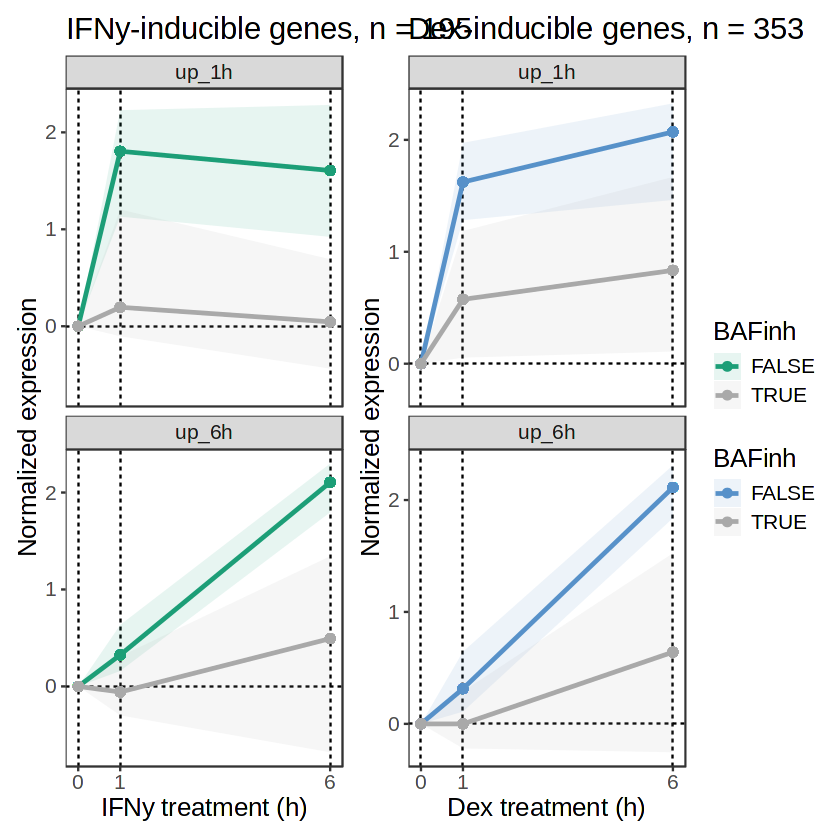

In [10]:
(lineplot_ifn_median | lineplot_dex_median) + plot_layout(guides="collect")
#ggsave("panelE_lineplot_median_iqr.pdf", width=8)

# Statistics

In [171]:
#stats (IFNy)
#wilcoxon rank-sum test within 1h and 6h induced sets - is expression lower with BAFinh?

ifn_for_stats <- ifn_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - ifn_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_ifn_inducible$category, Veh_BAFinh=Veh)

p1<- wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_1h",]$BAFinh_IFN_1h, ifn_for_stats[ifn_for_stats$cat=="up_1h",]$IFN_1h, alternative="less")$p.value
p2 <- wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_1h",]$BAFinh_IFN_6h, ifn_for_stats[ifn_for_stats$cat=="up_1h",]$IFN_6h, alternative="less")$p.value
p3 <- wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_6h",]$BAFinh_IFN_1h, ifn_for_stats[ifn_for_stats$cat=="up_6h",]$IFN_1h, alternative="less")$p.value
p4 <- wilcox.test(ifn_for_stats[ifn_for_stats$cat=="up_6h",]$BAFinh_IFN_6h, ifn_for_stats[ifn_for_stats$cat=="up_6h",]$IFN_6h, alternative="less")$p.value       

#stats (Dex)
#wilcoxon rank-sum test within 1h and 6h induced sets - is expression lower with BAFinh?

dex_for_stats <- dex_inducible_scale %>% 
    apply(MARGIN=2, FUN=function(x) x - dex_inducible_scale$Veh) %>%
    data.frame() %>% 
    mutate(cat=row.data_dex_inducible$category, Veh_BRM=Veh)

p5 <- wilcox.test(dex_for_stats[dex_for_stats$cat=="up_1h",]$BAFinh_Dex_1h, dex_for_stats[dex_for_stats$cat=="up_1h",]$Dex_1h, alternative="less")$p.value
p6 <- wilcox.test(dex_for_stats[dex_for_stats$cat=="up_1h",]$BAFinh_Dex_6h, dex_for_stats[dex_for_stats$cat=="up_1h",]$Dex_6h, alternative="less")$p.value
p7 <- wilcox.test(dex_for_stats[dex_for_stats$cat=="up_6h",]$BAFinh_Dex_1h, dex_for_stats[dex_for_stats$cat=="up_6h",]$Dex_1h, alternative="less")$p.value
p8 <- wilcox.test(dex_for_stats[dex_for_stats$cat=="up_6h",]$BAFinh_Dex_6h, dex_for_stats[dex_for_stats$cat=="up_6h",]$Dex_6h, alternative="less")$p.value       

In [178]:
pval.table <- 
    data.frame(
        time=rep(c(1,6), 4),
        stim=c(rep("IFN", 4), rep("Dex", 4)),
        gene_set=rep(c("up_1h", "up_1h", "up_6h", "up_6h"),2),
        p_raw=c(p1,p2,p3,p4,p5,p6,p7,p8)
    ) %>% mutate(padj=p.adjust(p_raw, "bonferroni"))
write.table(pval.table, "pval_table.tsv", sep='\t', row.names=F)